1. Laplcian Filter

Saving image.jp2 to image (1).jp2


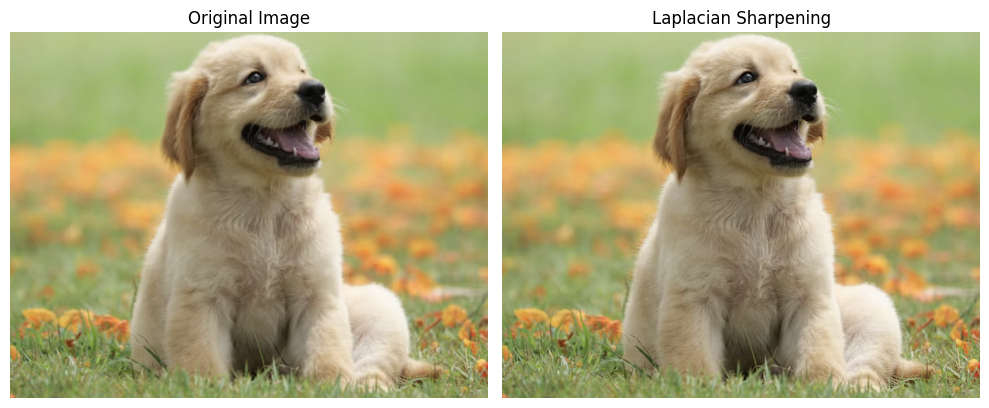

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
image = cv2.imread(next(iter(uploaded)))

if image is None:
    raise ValueError("Unable to read image")

laplacian = cv2.Laplacian(image, cv2.CV_64F)
sharpened = np.clip(image.astype(np.float64) - 0.5 * laplacian, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sharpened, cv2.COLOR_BGR2RGB))
plt.title("Laplacian Sharpening")
plt.axis("off")

plt.tight_layout()
plt.show()

2. Sobel Gradient Operator

Saving image.jp2 to image (2).jp2


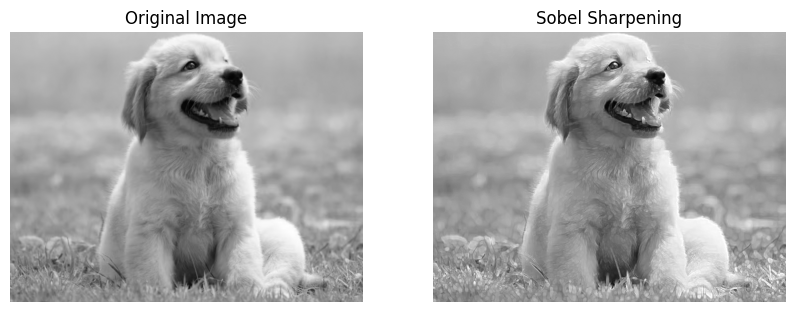

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
image = cv2.imread(next(iter(uploaded)))
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

sobel = np.sqrt(sobel_x**2 + sobel_y**2)
sobel = cv2.convertScaleAbs(sobel)

sharpened = cv2.addWeighted(gray, 1.0, sobel, 0.5, 0)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sharpened, cmap="gray")
plt.title("Sobel Sharpening")
plt.axis("off")
plt.show()

3. Canny Edge Detector


Saving image.jp2 to image (3).jp2


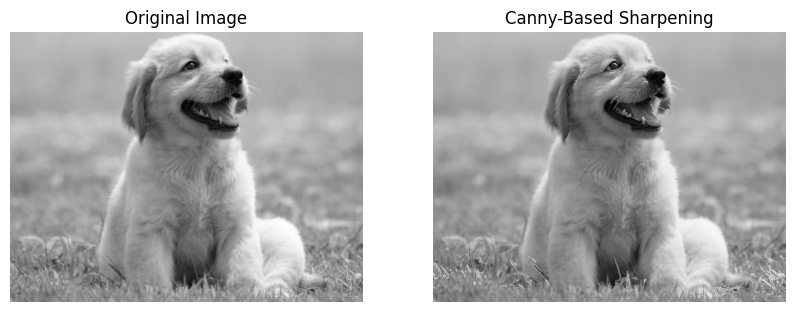

In [4]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
image = cv2.imread(next(iter(uploaded)))
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

edges = cv2.Canny(gray, 100, 200)
sharpened = cv2.addWeighted(gray, 1.0, edges, 0.5, 0)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sharpened, cmap="gray")
plt.title("Canny-Based Sharpening")
plt.axis("off")
plt.show()

4. Unsharp Masking

Saving image.jp2 to image (4).jp2


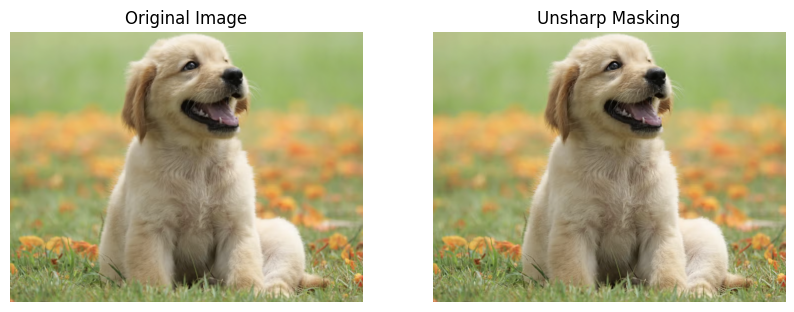

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
image = cv2.imread(next(iter(uploaded)))

blurred = cv2.GaussianBlur(image, (5, 5), 3)
sharpened = cv2.addWeighted(image, 1.5, blurred, -0.5, 0)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sharpened, cv2.COLOR_BGR2RGB))
plt.title("Unsharp Masking")
plt.axis("off")
plt.show()